In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


In [11]:
path = r"C:\Users\Surender\Downloads\train.csv"
df = pd.read_csv(path)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [12]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nInfo:")
df.info()

print("\nDescribe:")
display(df.describe(include="all").T)

print("\nMissing values:")
missing = df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
}))

Shape: (891, 12)

Columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Info:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Describe:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



Missing values:


,missing_count,missing_percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


In [13]:
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(f"\nValue counts for {col}:")
    display(df[col].value_counts(dropna=False))

print("\nSurvival rate:")
print(df["Survived"].value_counts(normalize=True).round(4))


Value counts for Survived:


Survived
0    549
1    342
Name: count, dtype: int64


Value counts for Pclass:


Pclass
3    491
1    216
2    184
Name: count, dtype: int64


Value counts for Sex:


Sex
male      577
female    314
Name: count, dtype: int64


Value counts for Embarked:


Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


Survival rate:
Survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


In [14]:
df_eda = df.copy()

df_eda["FamilySize"] = df_eda["SibSp"] + df_eda["Parch"] + 1
df_eda["IsAlone"] = (df_eda["FamilySize"] == 1).astype(int)

df_eda["AgeGroup"] = pd.cut(
    df_eda["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Adult", "MiddleAge", "Senior"]
)

df_eda["FareGroup"] = pd.qcut(
    df_eda["Fare"],
    q=4,
    labels=["Low", "MidLow", "MidHigh", "High"],
    duplicates="drop"
)

df_eda["Sex_male"] = (df_eda["Sex"] == "male").astype(int)

df_eda.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,IsAlone,AgeGroup,FareGroup,Sex_male
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0,Adult,Low,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,0,MiddleAge,High,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1,Adult,MidLow,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,0,Adult,High,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,1,Adult,MidLow,1


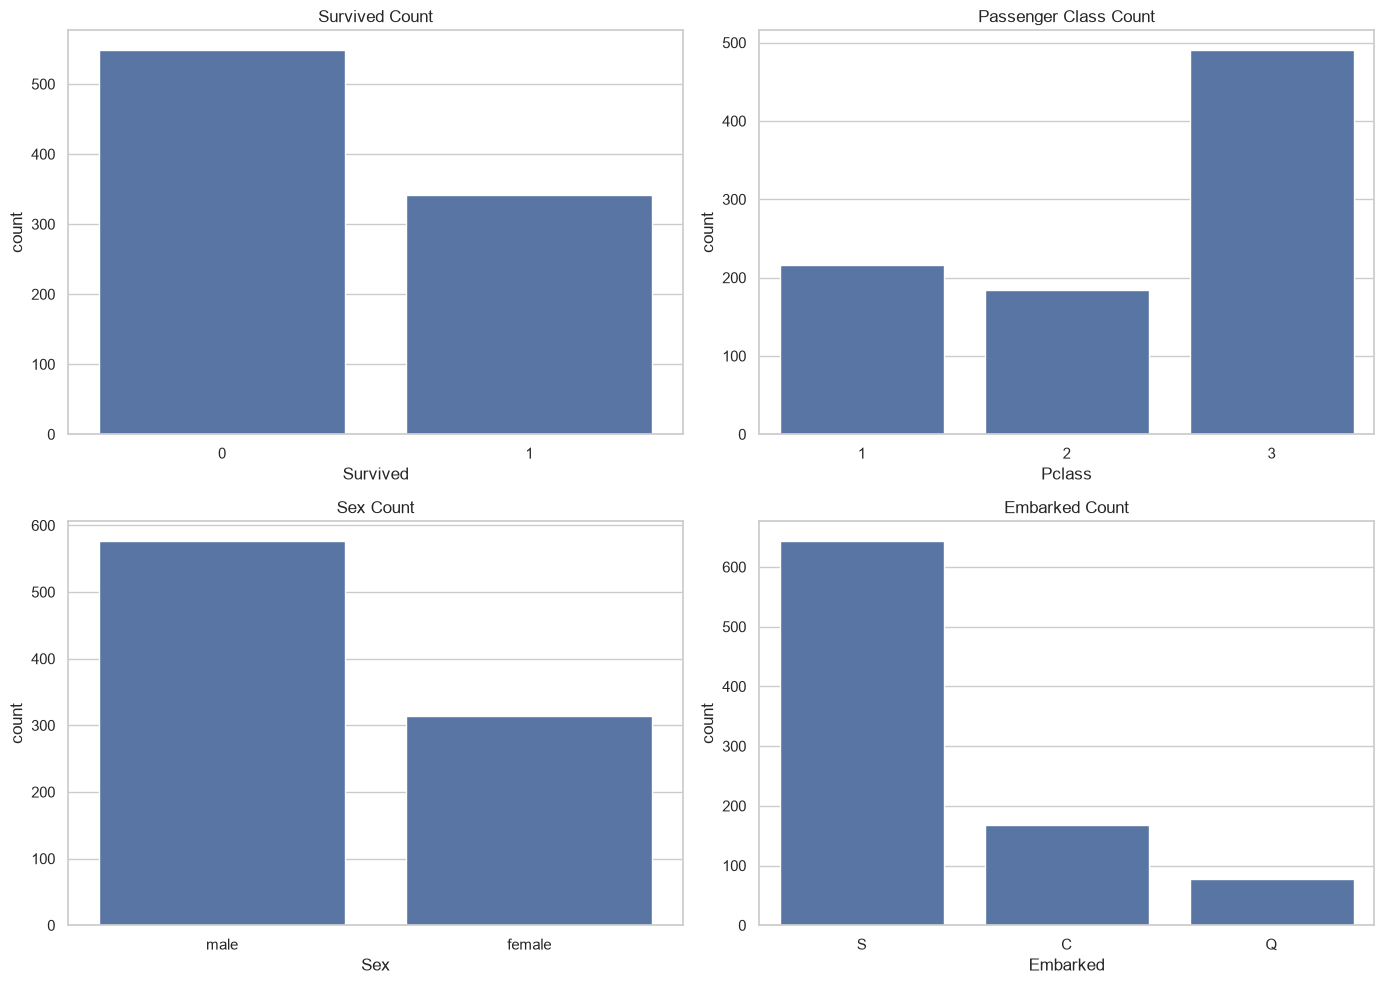

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df_eda, x="Survived", ax=axes[0, 0])
axes[0, 0].set_title("Survived Count")

sns.countplot(data=df_eda, x="Pclass", ax=axes[0, 1])
axes[0, 1].set_title("Passenger Class Count")

sns.countplot(data=df_eda, x="Sex", ax=axes[1, 0])
axes[1, 0].set_title("Sex Count")

sns.countplot(data=df_eda, x="Embarked", ax=axes[1, 1])
axes[1, 1].set_title("Embarked Count")

plt.tight_layout()
plt.show()

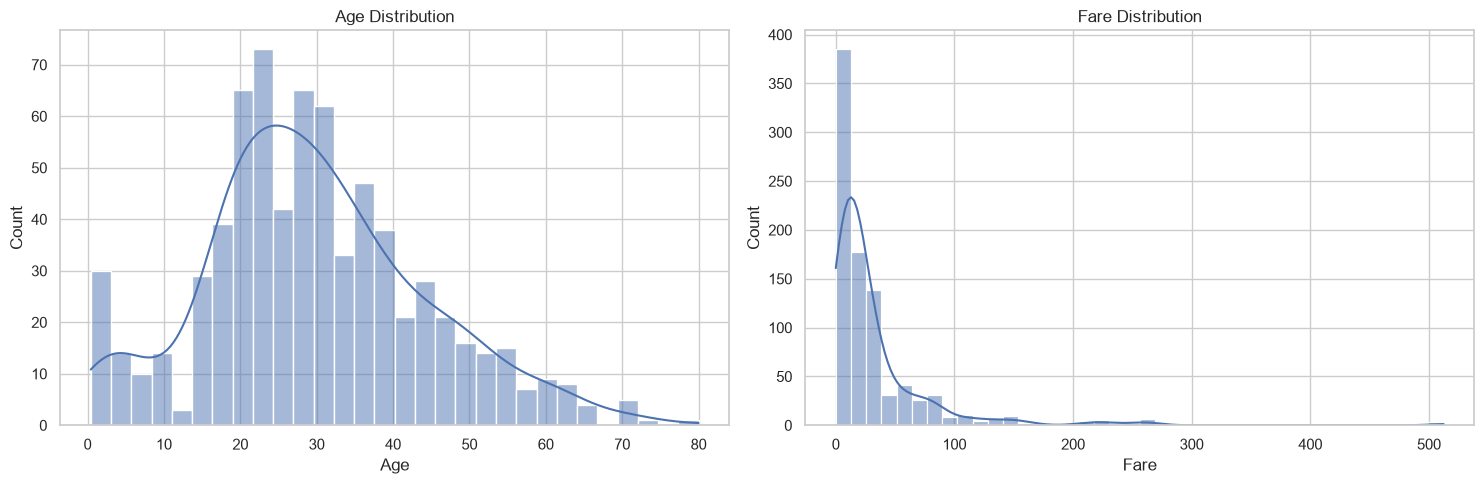

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_eda["Age"].dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.histplot(df_eda["Fare"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Fare Distribution")

plt.tight_layout()
plt.show()

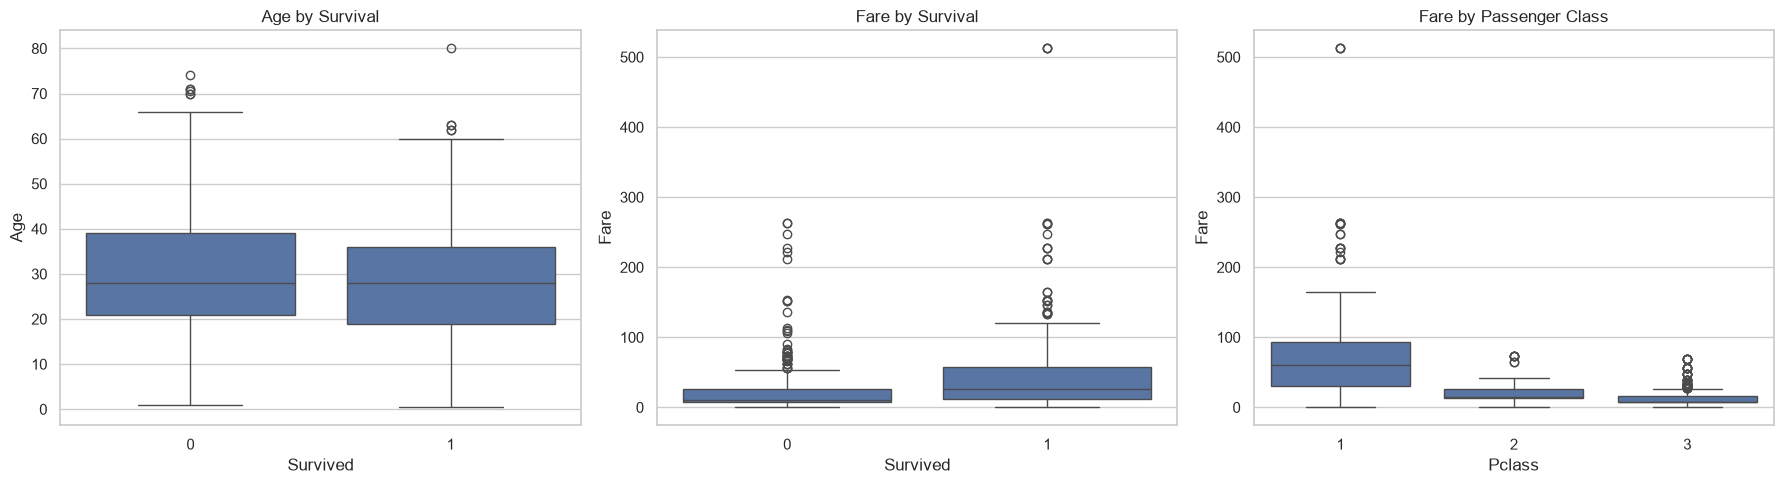

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df_eda, x="Survived", y="Age", ax=axes[0])
axes[0].set_title("Age by Survival")

sns.boxplot(data=df_eda, x="Survived", y="Fare", ax=axes[1])
axes[1].set_title("Fare by Survival")

sns.boxplot(data=df_eda, x="Pclass", y="Fare", ax=axes[2])
axes[2].set_title("Fare by Passenger Class")

plt.tight_layout()
plt.show()

In [18]:
def survival_table(col):
    return (
        df_eda.groupby(col, dropna=False)["Survived"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "survival_rate"})
        .assign(survival_rate=lambda x: (x["survival_rate"] * 100).round(2))
        .sort_values("survival_rate", ascending=False)
    )

print("Survival by Sex:")
display(survival_table("Sex"))

print("\nSurvival by Pclass:")
display(survival_table("Pclass"))

print("\nSurvival by Embarked:")
display(survival_table("Embarked"))

print("\nSurvival by FamilySize:")
display(survival_table("FamilySize"))

print("\nSurvival by AgeGroup:")
display(survival_table("AgeGroup"))

print("\nSurvival by FareGroup:")
display(survival_table("FareGroup"))

Survival by Sex:


,count,survival_rate
Sex,,
female,314,74.20
male,577,18.89



Survival by Pclass:


,count,survival_rate
Pclass,,
1,216,62.96
2,184,47.28
3,491,24.24



Survival by Embarked:


,count,survival_rate
Embarked,,
NaN,2,100.00
C,168,55.36
Q,77,38.96
S,644,33.70


... (2 outputs left out)


Survival by AgeGroup:


,count,survival_rate
AgeGroup,,
Child,69,57.97
Teen,70,42.86
MiddleAge,195,40.00
Adult,358,38.27
NaN,177,29.38
Senior,22,22.73



Survival by FareGroup:


,count,survival_rate
FareGroup,,
High,222,58.11
MidHigh,222,45.50
MidLow,224,30.36
Low,223,19.73


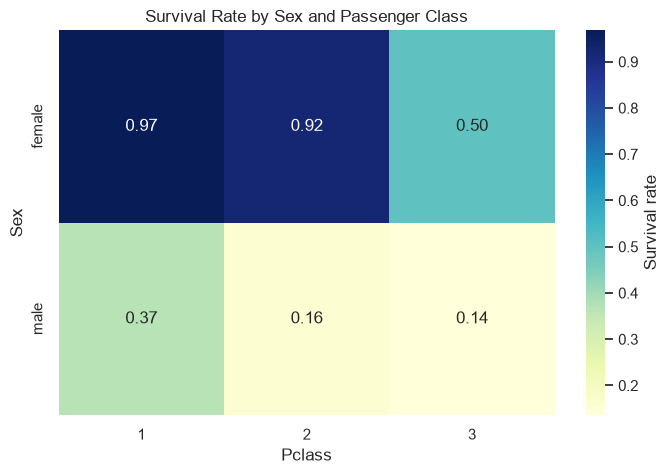

In [19]:
pivot_sex_class = df_eda.pivot_table(
    values="Survived",
    index="Sex",
    columns="Pclass",
    aggfunc="mean"
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    pivot_sex_class,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Survival rate"}
)
plt.title("Survival Rate by Sex and Passenger Class")
plt.show()

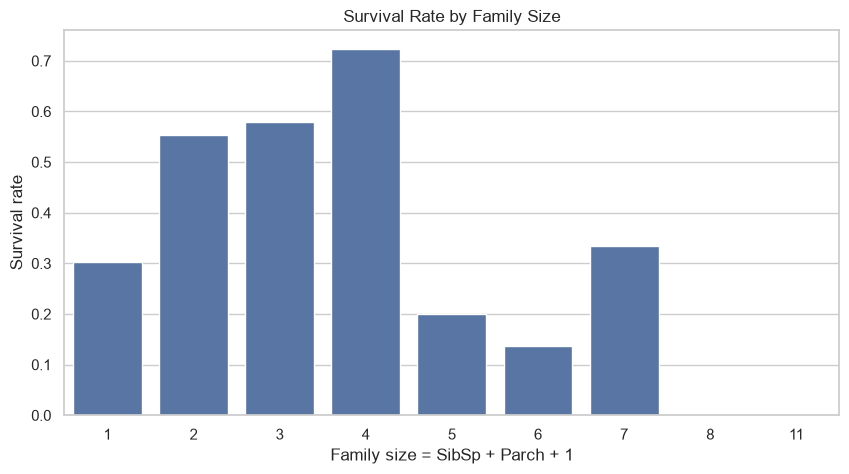

In [20]:
family_survival = (
    df_eda.groupby("FamilySize")["Survived"]
    .agg(["count", "mean"])
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(data=family_survival, x="FamilySize", y="mean")
plt.title("Survival Rate by Family Size")
plt.ylabel("Survival rate")
plt.xlabel("Family size = SibSp + Parch + 1")
plt.show()

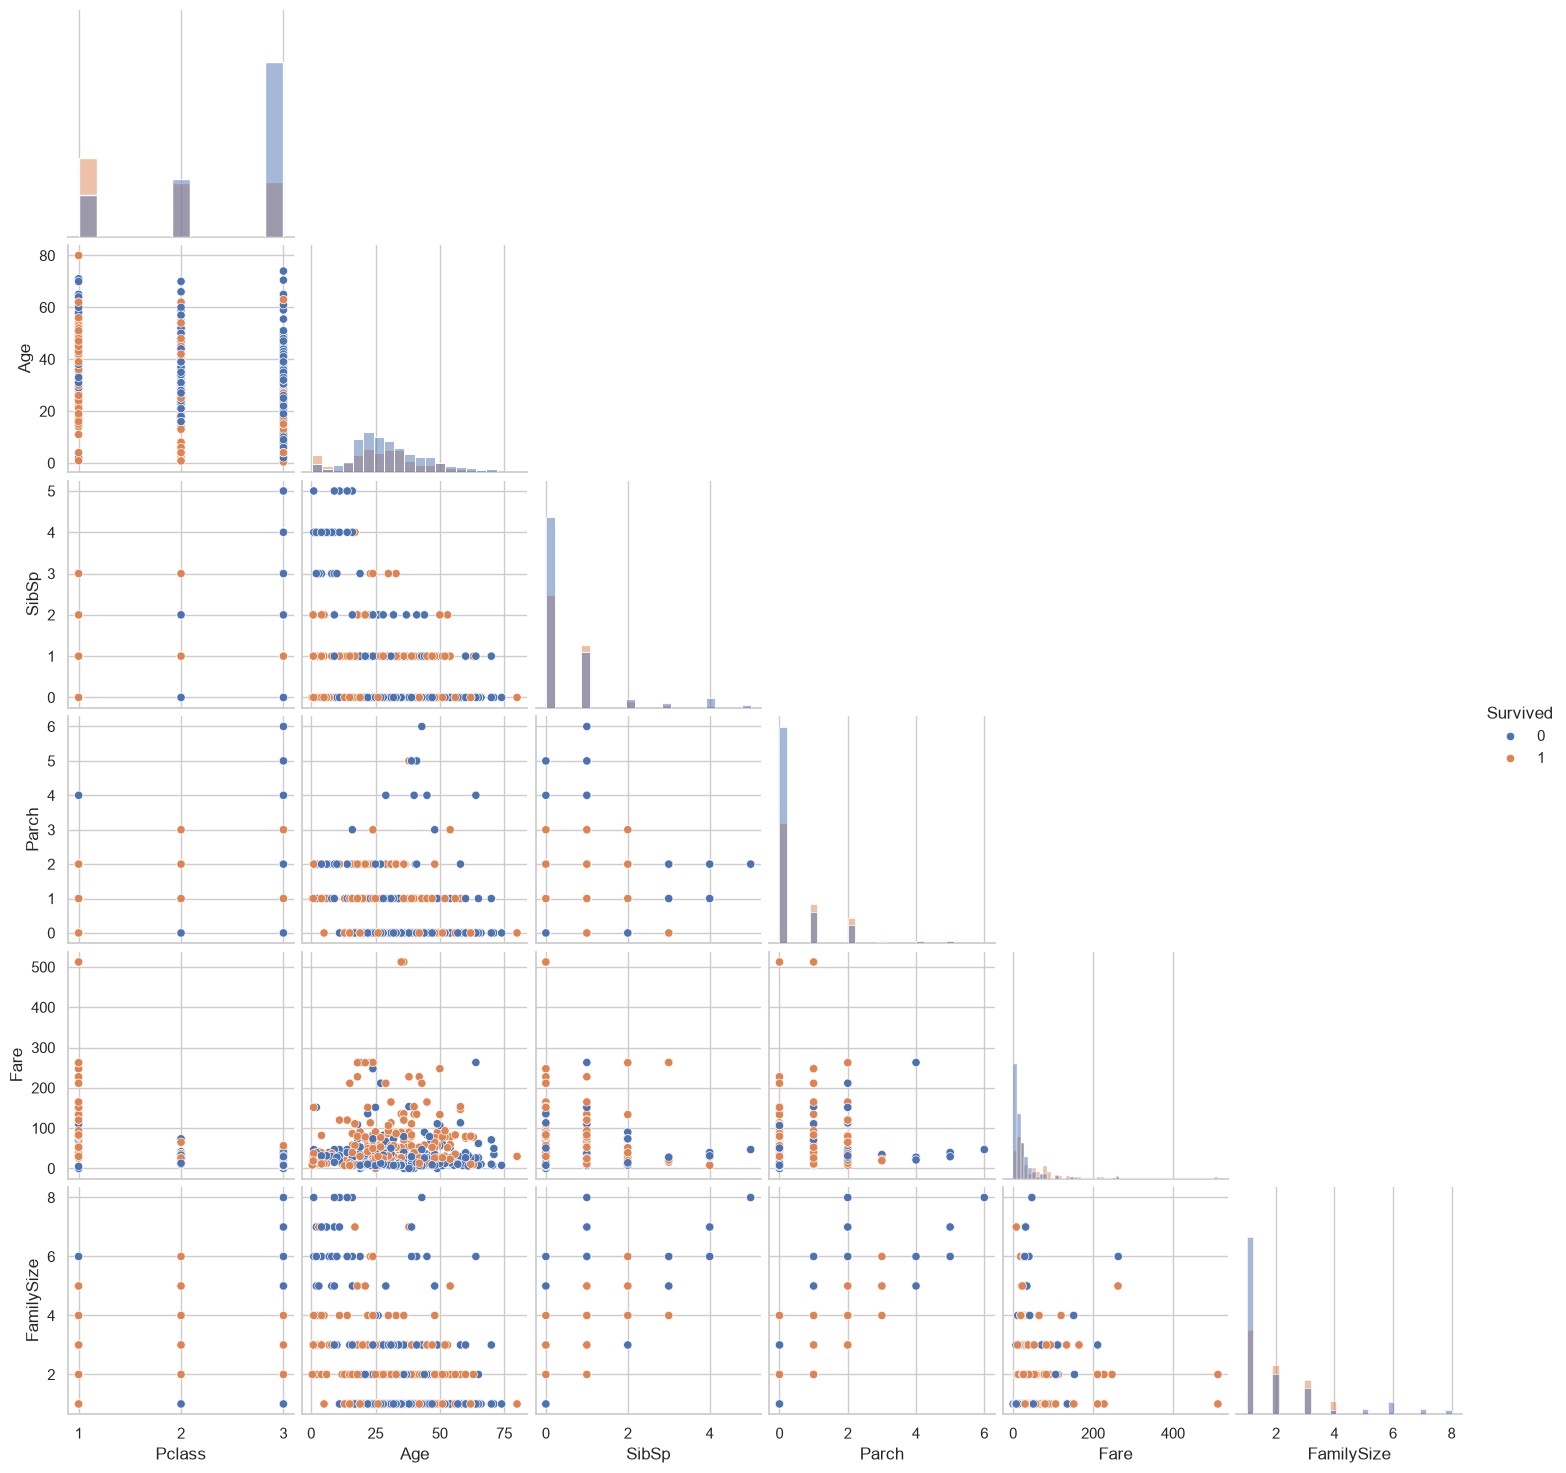

In [21]:
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]

sns.pairplot(
    df_eda[numeric_cols].dropna(),
    hue="Survived",
    diag_kind="hist",
    corner=True
)
plt.show()

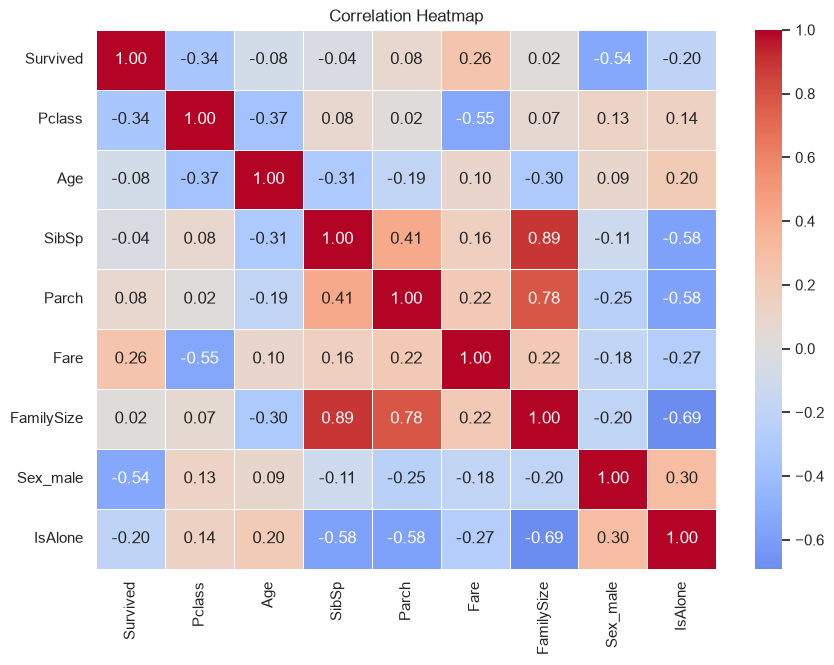

In [22]:
corr_cols = [
    "Survived", "Pclass", "Age", "SibSp", "Parch",
    "Fare", "FamilySize", "Sex_male", "IsAlone"
]

corr = df_eda[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.show()

In [23]:
# Fare outliers using IQR
Q1 = df_eda["Fare"].quantile(0.25)
Q3 = df_eda["Fare"].quantile(0.75)
IQR = Q3 - Q1

fare_outliers = df_eda[(df_eda["Fare"] < Q1 - 1.5 * IQR) |
                       (df_eda["Fare"] > Q3 + 1.5 * IQR)]

print("Number of Fare outliers by IQR rule:", len(fare_outliers))
display(fare_outliers[["PassengerId", "Name", "Pclass", "Fare", "Survived"]].head(10))

print("Zero Fare rows:", (df_eda["Fare"] == 0).sum())
print("Max Fare:", df_eda["Fare"].max())
print("Median Fare:", df_eda["Fare"].median())
print("Mean Fare:", round(df_eda["Fare"].mean(), 2))

Number of Fare outliers by IQR rule: 116


,PassengerId,Name,Pclass,Fare,Survived
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,71.2833,1
27,28,"Fortune, Mr. Charles Alexander",1,263.0000,0
31,32,"Spencer, Mrs. William Augustus (Marie Eugenie)",1,146.5208,1
34,35,"Meyer, Mr. Edgar Joseph",1,82.1708,0
52,53,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",1,76.7292,1
61,62,"Icard, Miss. Amelie",1,80.0000,1
62,63,"Harris, Mr. Henry Birkhardt",1,83.4750,0
72,73,"Hood, Mr. Ambrose Jr",2,73.5000,0
88,89,"Fortune, Miss. Mabel Helen",1,263.0000,1
102,103,"White, Mr. Richard Frasar",1,77.2875,0


Zero Fare rows: 15
Max Fare: 512.3292
Median Fare: 14.4542
Mean Fare: 32.2
